In [1]:
import yfinance as yf
import pandas as pd
import seaborn as sns
import numpy as np

In [2]:
tickers = ['SPY', 'IWM', 'EFA', 'VNQ', 'BIL', 'TLT', 'LQD', 'GLD', 'DBC']
df = pd.DataFrame()

start_date = '2007-05-30'
end_date = '2026-09-30'

In [3]:
for ticker in tickers:
   stock = yf.download(ticker, start=start_date, end=end_date, auto_adjust=True) #start, end date
   df[ticker] = stock['Close'].pct_change().dropna()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [4]:
print(df.apply(lambda c: c.first_valid_index()))   # first date per ticker

SPY   2007-05-31
IWM   2007-05-31
EFA   2007-05-31
VNQ   2007-05-31
BIL   2007-05-31
TLT   2007-05-31
LQD   2007-05-31
GLD   2007-05-31
DBC   2007-05-31
dtype: datetime64[s]


In [5]:
df.isna().sum()

SPY    0
IWM    0
EFA    0
VNQ    0
BIL    0
TLT    0
LQD    0
GLD    0
DBC    0
dtype: int64

In [6]:
df.reset_index(inplace=True)
df

,Date,SPY,IWM,EFA,VNQ,BIL,TLT,LQD,GLD,DBC
0,2007-05-31,-0.001043,0.005488,0.004961,-0.004037,0.000000,-0.001848,-0.000849,0.012670,0.009098
1,2007-06-01,0.004957,0.005103,0.006541,0.001394,0.000219,-0.005254,-0.003831,0.013732,0.007448
2,2007-06-04,0.000130,0.001063,0.002698,0.004047,0.000218,0.004558,0.001618,0.001505,0.008950
3,2007-06-05,-0.003958,-0.004010,-0.005136,-0.015873,0.000000,-0.006281,-0.003232,-0.002555,-0.003857
4,2007-06-06,-0.010750,-0.011131,-0.014380,-0.006784,0.000437,-0.000469,0.000858,0.000603,-0.000387
...,...,...,...,...,...,...,...,...,...,...
4859,2026-09-23,-0.007202,-0.018419,-0.015962,-0.014707,0.000218,-0.015780,-0.011419,-0.017972,0.013564
4860,2026-09-24,-0.000821,-0.000922,-0.002863,-0.003062,-0.000109,-0.012926,-0.007123,-0.003029,0.009124
4861,2026-09-25,0.005435,0.001101,0.010144,-0.001974,0.000437,-0.001259,0.000582,0.004391,-0.016878
4862,2026-09-28,-0.007441,-0.006916,-0.004926,-0.004396,0.000109,-0.008825,-0.007170,-0.039399,-0.003985


<Axes: >

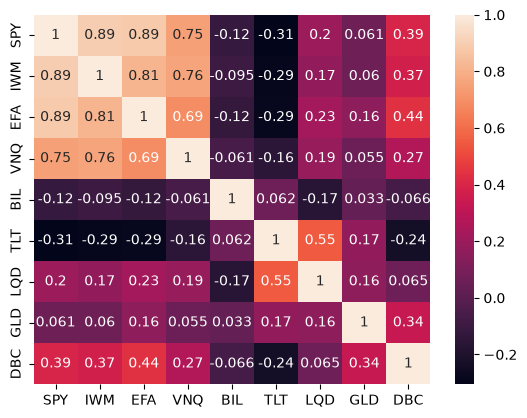

In [7]:
corr_df = df[['SPY', 'IWM', 'EFA', 'VNQ', 'BIL', 'TLT', 'LQD', 'GLD', 'DBC']]

sns.heatmap(corr_df.corr(), annot=True)

### dropping IWM as it is the least distinct asset

In [8]:
df = df[['Date','SPY', 'EFA', 'VNQ', 'BIL', 'TLT', 'LQD', 'GLD', 'DBC']]
df

,Date,SPY,EFA,VNQ,BIL,TLT,LQD,GLD,DBC
0,2007-05-31,-0.001043,0.004961,-0.004037,0.000000,-0.001848,-0.000849,0.012670,0.009098
1,2007-06-01,0.004957,0.006541,0.001394,0.000219,-0.005254,-0.003831,0.013732,0.007448
2,2007-06-04,0.000130,0.002698,0.004047,0.000218,0.004558,0.001618,0.001505,0.008950
3,2007-06-05,-0.003958,-0.005136,-0.015873,0.000000,-0.006281,-0.003232,-0.002555,-0.003857
4,2007-06-06,-0.010750,-0.014380,-0.006784,0.000437,-0.000469,0.000858,0.000603,-0.000387
...,...,...,...,...,...,...,...,...,...
4859,2026-09-23,-0.007202,-0.015962,-0.014707,0.000218,-0.015780,-0.011419,-0.017972,0.013564
4860,2026-09-24,-0.000821,-0.002863,-0.003062,-0.000109,-0.012926,-0.007123,-0.003029,0.009124
4861,2026-09-25,0.005435,0.010144,-0.001974,0.000437,-0.001259,0.000582,0.004391,-0.016878
4862,2026-09-28,-0.007441,-0.004926,-0.004396,0.000109,-0.008825,-0.007170,-0.039399,-0.003985


In [9]:
returns = df   # drops rows until every ticker has data

wealth = (1 + returns).cumprod()
stats = pd.DataFrame({
    'ann_return': (1 + returns).prod() ** (252 / len(returns)) - 1,
    'ann_vol': returns.std() * np.sqrt(252),
    'max_drawdown': (wealth / wealth.cummax() - 1).min(),
})
print(stats.round(3))

TypeError: Addition/subtraction of integers and integer-arrays with DatetimeArray is no longer supported.  Instead of adding/subtracting `n`, use `n * obj.freq`

In [ ]:
extremes = pd.DataFrame({
    'worst_day': returns.min(), 'worst_date': returns.idxmin(),
    'best_day': returns.max(),  'best_date': returns.idxmax(),
})
print(extremes)

     worst_day worst_date  best_day  best_date
SPY  -0.109423 2020-03-16  0.145197 2008-10-13
EFA  -0.111632 2008-09-29  0.158876 2008-10-13
VNQ  -0.195137 2008-12-01  0.170065 2008-11-24
BIL  -0.003910 2008-10-13  0.004351 2008-09-17
TLT  -0.066683 2020-03-17  0.075196 2020-03-20
LQD  -0.091111 2008-09-29  0.097677 2008-09-30
GLD  -0.102742 2026-01-30  0.112905 2008-09-17
DBC  -0.079444 2022-03-09  0.068744 2008-11-24


### merge asset's returns with regimes

In [17]:
df

,Date,SPY,EFA,VNQ,BIL,TLT,LQD,GLD,DBC
0,2007-05-31,-0.001043,0.004961,-0.004037,0.000000,-0.001848,-0.000849,0.012670,0.009098
1,2007-06-01,0.004957,0.006541,0.001394,0.000219,-0.005254,-0.003831,0.013732,0.007448
2,2007-06-04,0.000130,0.002698,0.004047,0.000218,0.004558,0.001618,0.001505,0.008950
3,2007-06-05,-0.003958,-0.005136,-0.015873,0.000000,-0.006281,-0.003232,-0.002555,-0.003857
4,2007-06-06,-0.010750,-0.014380,-0.006784,0.000437,-0.000469,0.000858,0.000603,-0.000387
...,...,...,...,...,...,...,...,...,...
4859,2026-09-23,-0.007202,-0.015962,-0.014707,0.000218,-0.015780,-0.011419,-0.017972,0.013564
4860,2026-09-24,-0.000821,-0.002863,-0.003062,-0.000109,-0.012926,-0.007123,-0.003029,0.009124
4861,2026-09-25,0.005435,0.010144,-0.001974,0.000437,-0.001259,0.000582,0.004391,-0.016878
4862,2026-09-28,-0.007441,-0.004926,-0.004396,0.000109,-0.008825,-0.007170,-0.039399,-0.003985


In [18]:
regimes = pd.read_csv('regime_states.csv')
regimes['Date'] = pd.to_datetime(regimes['Date'])
regimes = regimes.sort_values('Date')

cols = ['p_state0', 'p_state1', 'p_state2', 'hard_state']
regimes[cols] = regimes[cols].shift(1)
regimes = regimes.dropna(subset=cols)
regimes['hard_state'] = regimes['hard_state'].astype(int)

vix = yf.download('^VIX', start='2007-01-04', auto_adjust=True)['Close'].squeeze()   

D = '2022-11-22'    # the last HMM train date, from regime.index[3999]
train_vix = vix.loc[:D]
vix_scaled = ((vix - train_vix.mean()) / train_vix.std(ddof=0)).shift(1)
vix_scaled = vix_scaled.rename('vix_scaled').reset_index()   # columns: Date, vix_scaled
vix_scaled['Date'] = pd.to_datetime(vix_scaled['Date'])
df = df.merge(vix_scaled, on='Date', how='inner')

df = df.merge(regimes, on='Date', how='inner')
df = df.drop("split", axis='columns')
df = pd.get_dummies(df, columns=['hard_state'], dtype=int)
df

[*********************100%***********************]  1 of 1 completed


,Date,SPY,EFA,VNQ,BIL,TLT,LQD,GLD,DBC,vix_scaled,p_state0,p_state1,p_state2,hard_state_0,hard_state_1,hard_state_2
0,2007-05-31,-0.001043,0.004961,-0.004037,0.000000,-0.001848,-0.000849,0.012670,0.009098,-0.798224,0.999246,0.000754,7.907185e-08,1,0,0
1,2007-06-01,0.004957,0.006541,0.001394,0.000219,-0.005254,-0.003831,0.013732,0.007448,-0.774725,0.999674,0.000326,4.387363e-08,1,0,0
2,2007-06-04,0.000130,0.002698,0.004047,0.000218,0.004558,0.001618,0.001505,0.008950,-0.803565,0.999604,0.000396,2.322887e-08,1,0,0
3,2007-06-05,-0.003958,-0.005136,-0.015873,0.000000,-0.006281,-0.003232,-0.002555,-0.003857,-0.749090,0.999617,0.000383,2.235454e-08,1,0,0
4,2007-06-06,-0.010750,-0.014380,-0.006784,0.000437,-0.000469,0.000858,0.000603,-0.000387,-0.712774,0.999443,0.000557,3.247055e-08,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4859,2026-09-23,-0.007202,-0.015962,-0.014707,0.000218,-0.015780,-0.011419,-0.017972,0.013564,-0.650823,0.985719,0.014249,3.154755e-05,1,0,0
4860,2026-09-24,-0.000821,-0.002863,-0.003062,-0.000109,-0.012926,-0.007123,-0.003029,0.009124,-0.547215,0.994780,0.005215,4.707372e-06,1,0,0
4861,2026-09-25,0.005435,0.010144,-0.001974,0.000437,-0.001259,0.000582,0.004391,-0.016878,-0.494876,0.995298,0.004701,1.034517e-06,1,0,0
4862,2026-09-28,-0.007441,-0.004926,-0.004396,0.000109,-0.008825,-0.007170,-0.039399,-0.003985,-0.580326,0.996467,0.003532,8.644285e-07,1,0,0


In [23]:
df.to_csv('full_dataset.csv',index=False)

### TRAIN SET UP TO 2022-11-22, TEST SET AFTERWARDS

In [ ]:
regimes.iloc[3999]

Date          2022-11-22 00:00:00
p_state0                      0.0
p_state1                 0.999038
p_state2                 0.000961
hard_state                      1
split                        test
Name: 4000, dtype: object